# 01 · Data exploration

The cleaned dataset from Phase 2 (`data/processed/documents.parquet`): class balance,
documents per year, top institutions and abstract lengths. Figures are saved to `reports/figures/`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
FIG = Path("reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet("data/processed/documents.parquet")
splits = pd.read_parquet("data/processed/splits.parquet")
summary = json.loads(Path("reports/cleaning_summary.json").read_text())
print(f"{len(df):,} documents, {df['institution'].nunique():,} institutions")
df.head(3)[["doc_id", "source", "title", "institution_name", "country", "year", "domain"]]

30,000 documents, 5,764 institutions


,doc_id,source,title,institution_name,country,year,domain
0,PAP-W1205555590,paper,Prosody prediction for arabic via the open-sou...,University of Jordan,JO,2021,Artificial Intelligence
1,PAP-W13134032,paper,Using Cryptographic Hash Functions for Discret...,University of Wollongong,AU,2020,Cybersecurity
2,PAP-W1512170369,paper,On the Difficulty of Constructing Cryptographi...,University of Wollongong,AU,2020,Cybersecurity


## Cleaning steps
Records loaded and removed at each step (from `reports/cleaning_summary.json`).

In [2]:
pd.Series({k: v for k, v in summary.items() if k.startswith("dropped")} | {"loaded_papers": summary["loaded"]["paper"], "loaded_patents": summary["loaded"]["patent"]})

dropped_short_or_missing_abstract      609
dropped_non_english_abstract          1433
dropped_duplicate_title                212
dropped_no_institution                   0
loaded_papers                        22004
loaded_patents                       14906
dtype: int64

## Class balance
Each domain holds 6,000 documents (20%), well under the 30% limit. Robotics and Cybersecurity
have fewer university patents, so papers fill the gap.

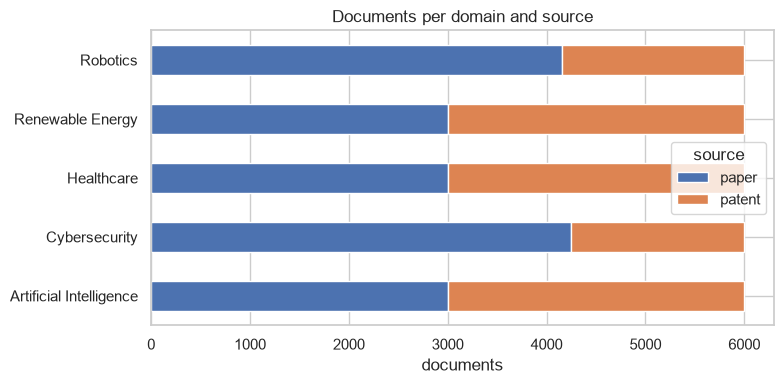

source,paper,patent,total,share
domain,,,,
Artificial Intelligence,3000,3000,6000,0.2
Cybersecurity,4248,1752,6000,0.2
Healthcare,3000,3000,6000,0.2
Renewable Energy,3000,3000,6000,0.2
Robotics,4158,1842,6000,0.2


In [3]:
counts = df.groupby(["domain", "source"]).size().unstack()
ax = counts.plot.barh(stacked=True, figsize=(8, 4), color=["#4C72B0", "#DD8452"])
ax.set_xlabel("documents"); ax.set_ylabel(""); ax.set_title("Documents per domain and source")
plt.tight_layout(); plt.savefig(FIG / "class_balance.png", dpi=150); plt.show()
counts.assign(total=counts.sum(axis=1), share=lambda t: (t.total / t.total.sum()).round(3))

## Documents per year

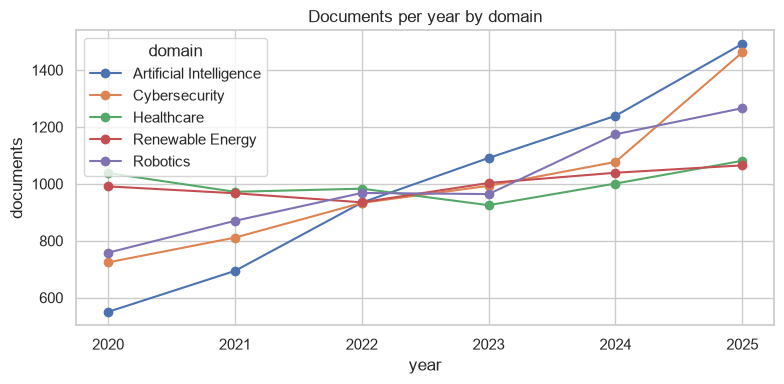

domain,Artificial Intelligence,Cybersecurity,Healthcare,Renewable Energy,Robotics
year,,,,,
2020,550,724,1038,991,758
2021,694,811,972,967,870
2022,934,933,983,935,968
2023,1091,993,925,1003,964
2024,1239,1077,1001,1039,1174
2025,1492,1462,1081,1065,1266


In [4]:
per_year = df.groupby(["year", "domain"]).size().unstack()
ax = per_year.plot(marker="o", figsize=(8, 4))
ax.set_ylabel("documents"); ax.set_title("Documents per year by domain")
plt.tight_layout(); plt.savefig(FIG / "documents_per_year.png", dpi=150); plt.show()
per_year

## Top institutions and countries

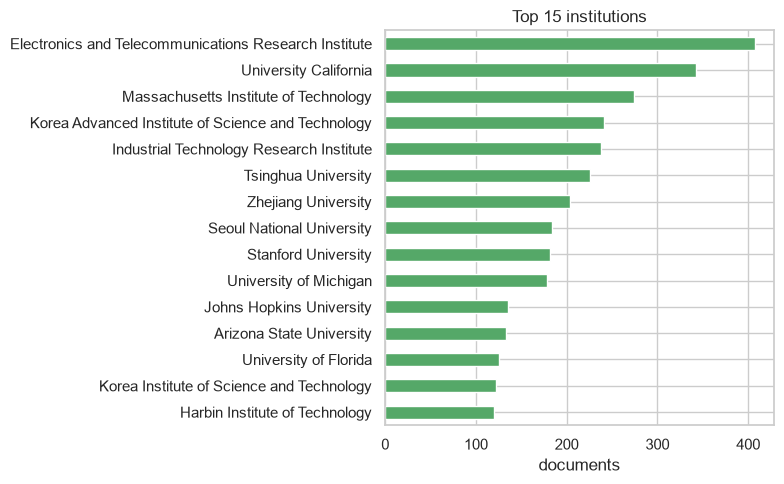

Institutions with both patents and papers: 599 of 5,764


country
CN    7098
US    6666
KR    2422
IN    1515
JP    1042
TW     784
GB     705
DE     604
ID     556
SA     509
Name: count, dtype: int64

In [5]:
top = df.groupby("institution_name").size().nlargest(15).sort_values()
ax = top.plot.barh(figsize=(8, 5), color="#55A868")
ax.set_xlabel("documents"); ax.set_ylabel(""); ax.set_title("Top 15 institutions")
plt.tight_layout(); plt.savefig(FIG / "top_institutions.png", dpi=150); plt.show()
both = df.groupby("institution")["source"].nunique()
print(f"Institutions with both patents and papers: {(both == 2).sum():,} of {len(both):,}")
df["country"].value_counts().head(10)

## Abstract lengths

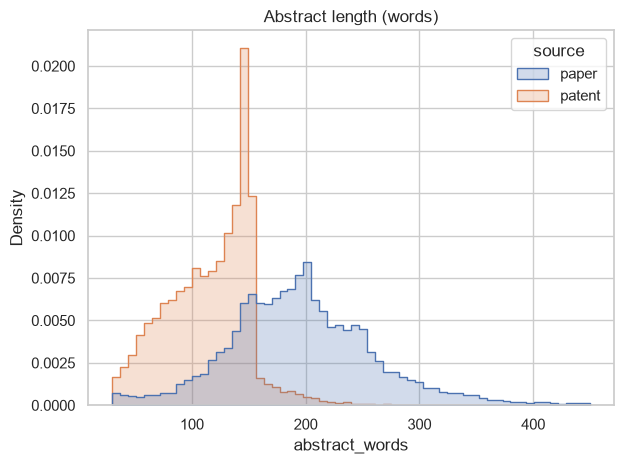

,count,mean,std,min,25%,50%,75%,max
source,,,,,,,,
paper,17406.0,198.7,80.2,30.0,154.0,193.0,234.0,2334.0
patent,12594.0,115.4,37.5,30.0,88.0,121.0,144.0,419.0


In [6]:
df["abstract_words"] = df["abstract"].str.split().str.len()
ax = sns.histplot(data=df, x="abstract_words", hue="source", bins=60, binrange=(30, 450), element="step", stat="density", common_norm=False)
ax.set_title("Abstract length (words)")
plt.tight_layout(); plt.savefig(FIG / "abstract_lengths.png", dpi=150); plt.show()
df.groupby("source")["abstract_words"].describe().round(1)

## Splits
Stratified 70/15/15 by domain with seed 42.

In [7]:
splits.merge(df[["doc_id", "domain"]], on="doc_id").groupby(["split", "domain"]).size().unstack()

domain,Artificial Intelligence,Cybersecurity,Healthcare,Renewable Energy,Robotics
split,,,,,
test,900,900,900,900,900
train,4200,4200,4200,4200,4200
val,900,900,900,900,900
